# Legal document classification and model benchmarking

<a id="overview"></a>
## 1. Overview

### Executive summary

The task predicts the legal domain of French court decisions: civil (CIV), criminal (CRIM), commercial (COM), or social/employment (SOC). The labels support a search filter.
After cleaning, the dataset contains **27,855 decisions**: 22,284 for development and 5,571 for testing.

**Macro-F1 is the main metric:** it averages the four class F1 scores with equal weight. Accuracy is secondary because CIV and SOC dominate the dataset.

**Test results on the same unseen 5,571 decisions**

| Approach | Macro-F1 | Accuracy |
|---|---:|---:|
| TF-IDF + LinearSVC | **0.970** | **0.983** |
| Fine-tuned [JuriBERT-base](https://huggingface.co/dascim/juribert-base) | 0.958 | 0.980 |
| Jev, zero-shot | 0.800 | 0.875 |

**Baseline selection: five-fold cross-validation on train+validate data**

| Approach | Mean macro-F1 | Fold std. | OOF accuracy |
|---|---:|---:|---:|
| TF-IDF + LinearSVC | 0.968 | 0.005 | 0.983 |
| TF-IDF + Logistic Regression | 0.950 | 0.005 | 0.970 |

Out-of-fold (OOF) predictions use each fold's validation records. Logistic Regression was evaluated through cross-validation only, separately from the final test.

LinearSVC has the best test results with these settings. More compute and tuning time may improve JuriBERT.

### Contents

1. [Overview](#overview)
2. [Data preparation](#data-preparation)
3. [Classical ML](#classical-ml)
4. [JuriBERT](#juribert)
5. [Jev](#jev)
6. [Conclusion](#conclusion)

In [4]:
%matplotlib inline

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path("data")
LABELS = ["CIV", "CRIM", "COM", "SOC"]
RANDOM_STATE = 42


<a id="data-preparation"></a>
## 2. Data preparation

<a id="data-loading"></a>
### 2.1 Load data

Four CSV files contain decision texts and labels. Source-based IDs track records during cleaning and evaluation.

In [5]:
frames = []
for label in LABELS:
    frame = pd.read_csv(
        DATA_DIR / f"{label}.csv",
        header=None, names=["text", "label"],
        dtype=str, encoding="utf-8", keep_default_na=False,
    )
    assert frame.index.equals(pd.RangeIndex(len(frame))), "Unexpected CSV structure"
    assert frame["label"].eq(label).all(), f"Unexpected label in {label}.csv"
    frame["record_id"] = label + ":" + (frame.index + 1).astype(str)
    frames.append(frame)

df = pd.concat(frames, ignore_index=True)
del frames, frame
print(f"{len(df):,} decisions across {df['label'].nunique()} classes")


27,998 decisions across 4 classes


### 2.2 Exploratory data analysis

Class counts show label imbalance. Text lengths are measured in raw characters, including HTML. Only the length histogram excludes blank texts.

,records,share_pct,median_chars
label,,,
CIV,13087,46.7,11817.0
CRIM,384,1.4,13177.0
COM,2265,8.1,13075.0
SOC,12262,43.8,14386.0


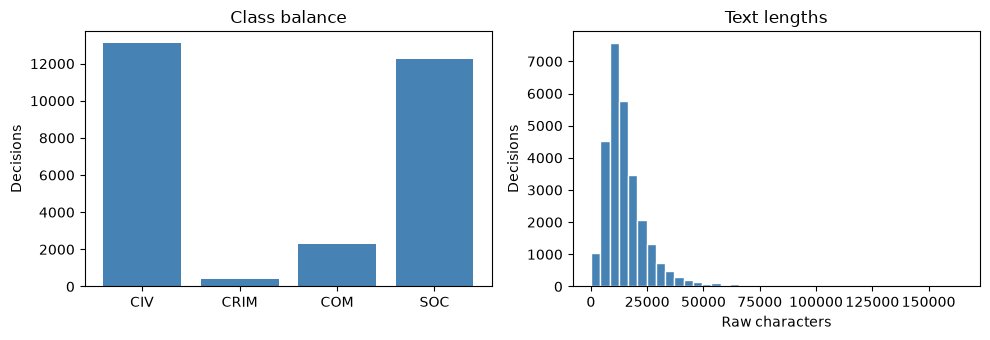

In [5]:
lengths = df["text"].str.len()
blank = df["text"].str.strip().eq("")
counts = df["label"].value_counts().reindex(LABELS)

summary = counts.rename("records").to_frame()
summary["share_pct"] = (100 * counts / len(df)).round(1)
summary["median_chars"] = lengths.groupby(df["label"]).median().reindex(LABELS)
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].bar(counts.index, counts.values, color="steelblue")
axes[0].set(title="Class balance", ylabel="Decisions")
axes[1].hist(lengths[~blank], bins=40, color="steelblue", edgecolor="white")
axes[1].set(title="Text lengths", xlabel="Raw characters", ylabel="Decisions")
fig.tight_layout()
plt.show()


### 2.3 Quality checks

Cleaning may reveal further duplicates.

In [6]:
nonblank = df.loc[~blank]
html = df["text"].str.contains(r"</?(?:p|br|div|span|html|body|table)\b", case=False)
label_counts = nonblank.groupby("text", sort=False)["label"].nunique()
conflicting_texts = label_counts[label_counts > 1].index

print(f"Blank texts: {blank.sum():,}")
print(f"Texts with common HTML tags: {html.mean():.1%}")
print(f"Extra exact copies (nonblank): {nonblank.duplicated('text').sum():,}")
print(f"Texts with conflicting labels: {len(conflicting_texts):,}")
display(nonblank.loc[nonblank["text"].isin(conflicting_texts), ["record_id", "label"]])


Blank texts: 4
Texts with common HTML tags: 97.2%
Extra exact copies (nonblank): 126
Texts with conflicting labels: 1


,record_id,label
1263,CIV:1264,CIV
19937,SOC:4202,SOC


- CRIM is only 1.4% of the raw data, making per-class scores important.
- Most texts contain HTML.
- Four blanks, 126 extra exact copies, and a CIV/SOC label conflict need attention before splitting.

<a id="cleaning"></a>
### 2.4 Clean and preprocess

Cleaning removes HTML and normalizes spacing while keeping accents, punctuation, negation, and a copy of the original text.

- Empty texts and two reviewed incomplete records (`COM:518`, `SOC:2048`) are removed.
- All copies with conflicting labels are removed. Other duplicates are reduced to one copy after normalization, ignoring case.
- Each removal is recorded.

In [7]:
from html import unescape
from unicodedata import normalize
from bs4 import BeautifulSoup


def clean_text(text):
    # Two passes handle the nested HTML entities found in this dataset.
    text = unescape(unescape(text))
    soup = BeautifulSoup(text, "html.parser")
    for tag in soup(["script", "style"]):
        tag.decompose()
    text = soup.get_text(" ", strip=True)
    return " ".join(normalize("NFC", text).split())


work = df.copy()
work["text_clean"] = work["text"].map(clean_text)
work["text_key"] = work["text_clean"].str.casefold()


In [8]:
reviewed_exclusions = {
    "COM:518": "Heading only",
    "SOC:2048": "Empty export",
}
reason = work["record_id"].map(reviewed_exclusions).fillna("")
reason.loc[reason.eq("") & work["text_clean"].eq("")] = "Empty text"

# Exclude every copy with conflicting labels before deduplicating.
valid = work.loc[reason.eq("")]
label_counts = valid.groupby("text_key", sort=False)["label"].transform("nunique")
reason.loc[label_counts.index[label_counts.gt(1)]] = "Conflicting labels"

valid = work.loc[reason.eq("")]
reason.loc[valid.index[valid.duplicated("text_key")]] = "Duplicate text"

exclusion_log = work.loc[reason.ne(""), ["record_id", "label"]].copy()
exclusion_log["reason"] = reason.loc[reason.ne("")]
clean_df = work.loc[reason.eq("")].drop(columns="text_key").reset_index(drop=True)

assert len(clean_df) + len(exclusion_log) == len(df)
assert clean_df["text_clean"].str.len().gt(0).all()
assert not clean_df["text_clean"].str.casefold().duplicated().any()


In [9]:
print(f"Decisions: {len(df):,} → {len(clean_df):,}")
display(exclusion_log["reason"].value_counts().rename("excluded").to_frame())
display(pd.DataFrame({
    "before": df["label"].value_counts(),
    "after": clean_df["label"].value_counts(),
}).reindex(LABELS))

example = clean_df.iloc[0]
print("Before:", repr(example["text"][:200]))
print("After: ", example["text_clean"][:200])


Decisions: 27,998 → 27,855


,excluded
reason,
Duplicate text,135
Empty text,4
Conflicting labels,2
Heading only,1
Empty export,1


,before,after
label,,
CIV,13087,13073
CRIM,384,383
COM,2265,2250
SOC,12262,12149


Cleaning keeps **27,855 of 27,998 decisions**. Only exact normalized matches count as duplicates; near-duplicates are not checked.

<a id="data-split"></a>
### 2.5 Development/test split

The split keeps **20% for testing** and **80% for development**, preserving class proportions. A fixed seed makes it repeatable, and all final evaluations use the same test records.

- Linear models use five-fold cross-validation, then LinearSVC fits all development data.
- JuriBERT uses five fixed epochs on all development data, without separate validation.
- Jev uses zero-shot classification, with no task-specific training.

In [10]:
from sklearn.model_selection import train_test_split, StratifiedKFold


dev_df, test_df = train_test_split(
    clean_df, test_size=0.2, stratify=clean_df["label"], random_state=RANDOM_STATE
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

X_dev, y_dev = dev_df["text_clean"], dev_df["label"]
X_test, y_test = test_df["text_clean"], test_df["label"]

assert len(dev_df) + len(test_df) == len(clean_df)
assert set(dev_df["record_id"]).isdisjoint(test_df["record_id"])
assert set(X_dev.str.casefold()).isdisjoint(X_test.str.casefold())

print(f"Development: {len(dev_df):,} | Test: {len(test_df):,}")
split_summary = pd.DataFrame({
    "development": y_dev.value_counts(),
    "test": y_test.value_counts(),
    "development_pct": y_dev.value_counts(normalize=True).mul(100).round(1),
    "test_pct": y_test.value_counts(normalize=True).mul(100).round(1),
}).reindex(LABELS)
display(split_summary)


Development: 22,284 | Test: 5,571


,development,test,development_pct,test_pct
label,,,,
CIV,10458,2615,46.9,46.9
CRIM,307,76,1.4,1.4
COM,1800,450,8.1,8.1
SOC,9719,2430,43.6,43.6


<a id="classical-ml"></a>
## 3. Classical ML

### 3.1 TF-IDF features

Both linear models use single words and two-word phrases. TF-IDF weights terms by their frequency within a decision and rarity across training documents.
The vocabulary is limited to 50,000 features. Sublinear term frequency reduces the effect of repetition.

The sparse feature preview uses the first fold: TF-IDF fits its training texts and transforms its validation texts.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

TFIDF_PARAMS = {
    "ngram_range": (1, 2),
    "min_df": 2,                 # Ignore terms found in only one training document.
    "sublinear_tf": True,        # Reduce the influence of repeated terms.
    "max_features": 50_000,       # Bound the vocabulary size.
}

preview_train_idx, preview_val_idx = next(cv.split(X_dev, y_dev))
preview_tfidf = TfidfVectorizer(**TFIDF_PARAMS)
X_preview_train = preview_tfidf.fit_transform(X_dev.iloc[preview_train_idx])
X_preview_val = preview_tfidf.transform(X_dev.iloc[preview_val_idx])

print(f"Training matrix:   {X_preview_train.shape} (decisions, features)")
print(f"Validation matrix: {X_preview_val.shape}")
print(f"Nonzero entries: {X_preview_train.nnz / (X_preview_train.shape[0] * X_preview_train.shape[1]):.1%}")


Training matrix:   (17827, 50000) (decisions, features)
Validation matrix: (4457, 50000)
Nonzero entries: 3.0%


In [14]:
# Display three decisions using the first decision's six highest-weight terms.
row = X_preview_train[0]
top_columns = row.indices[row.data.argsort()[-6:][::-1]]
feature_names = preview_tfidf.get_feature_names_out()

feature_preview = pd.DataFrame(
    X_preview_train[:3, top_columns].toarray(),
    index=dev_df.iloc[preview_train_idx[:3]]["record_id"],
    columns=feature_names[top_columns],
)
display(feature_preview.round(3))


Each cross-validation pipeline fits TF-IDF within its training fold. Validation texts do not affect its vocabulary or weights.

### 3.2 Compare the linear baselines

Both models use the same TF-IDF settings, five folds, `C=1`, and balanced weights that give smaller classes more influence. Hyperparameter optimization is skipped to save computation time.

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score, accuracy_score, classification_report

models = {
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(**TFIDF_PARAMS)),
        ("classifier", LogisticRegression(C=1.0, class_weight="balanced", max_iter=1000)),
    ]),
    "LinearSVC": Pipeline([
        ("tfidf", TfidfVectorizer(**TFIDF_PARAMS)),
        ("classifier", LinearSVC(
            C=1.0, class_weight="balanced", dual="auto",
            max_iter=5000, random_state=RANDOM_STATE,
        )),
    ]),
}


Each OOF prediction comes from a model that did not train on that record. Macro-F1 is calculated per fold; combined predictions provide accuracy and per-class scores. Folds run one after another to limit memory use.

In [16]:
cv_splits = list(cv.split(X_dev, y_dev))
results, class_reports = [], {}
oof_predictions = pd.DataFrame(
    {"label": y_dev.to_numpy()}, index=dev_df["record_id"]
)

for name, model in models.items():
    print(f"Evaluating {name}...", flush=True)
    predictions = cross_val_predict(model, X_dev, y_dev, cv=cv_splits, n_jobs=1)
    oof_predictions[name] = predictions

    fold_scores = pd.Series([
        f1_score(y_dev.iloc[val_idx], predictions[val_idx],
                 labels=LABELS, average="macro", zero_division=0)
        for _, val_idx in cv_splits
    ])
    results.append({
        "model": name,
        "macro_f1_mean": fold_scores.mean(),
        "macro_f1_std": fold_scores.std(ddof=0),
        "oof_accuracy": accuracy_score(y_dev, predictions),
    })
    report = classification_report(
        y_dev, predictions, labels=LABELS, output_dict=True, zero_division=0
    )
    class_reports[name] = pd.DataFrame(report).T.loc[LABELS]
    print(f"Macro-F1: {fold_scores.mean():.3f}")


Evaluating Logistic Regression...
Macro-F1: 0.950
Evaluating LinearSVC...
Macro-F1: 0.968


In [17]:
cv_results = pd.DataFrame(results).set_index("model").sort_values(
    "macro_f1_mean", ascending=False
)
per_class_results = pd.concat(class_reports, names=["model", "class"])
per_class_results["support"] = per_class_results["support"].astype(int)

display(cv_results.round(3))
display(per_class_results.round(3))


,macro_f1_mean,macro_f1_std,oof_accuracy
model,,,
LinearSVC,0.968,0.005,0.983
Logistic Regression,0.950,0.005,0.970


precision  recall  f1-score  support
model               class                                      
Logistic Regression CIV        0.986   0.952     0.969    10458
                    CRIM       0.977   0.980     0.979      307
                    COM        0.783   0.956     0.861     1800
                    SOC        0.996   0.992     0.994     9719
LinearSVC           CIV        0.982   0.982     0.982    10458
                    CRIM       0.984   0.987     0.985      307
                    COM        0.915   0.905     0.910     1800
                    SOC        0.996   0.997     0.996     9719

Fold standard deviation shows how scores vary across folds. It is not a confidence interval. LinearSVC's OOF confusion matrix shows errors as percentages, with each row totaling 100%.

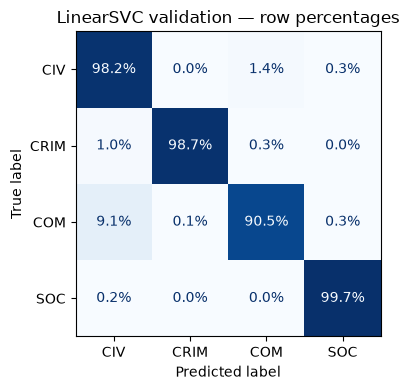

In [21]:
# Inspect LinearSVC validation errors: rows = actual class, columns = prediction.
from sklearn.metrics import ConfusionMatrixDisplay

svc_predictions = oof_predictions["LinearSVC"]
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    oof_predictions["label"], svc_predictions, labels=LABELS,
    normalize="true", values_format=".1%", cmap="Blues", colorbar=False, ax=ax,
)
ax.set_title("LinearSVC validation")
plt.tight_layout()
plt.show()


### 3.3 Fit the selected baseline

A new LinearSVC pipeline learns TF-IDF and the classifier on all development data, keeping the baseline settings fixed.

In [22]:
from sklearn.base import clone

full_svc = clone(models["LinearSVC"])
full_svc.fit(X_dev, y_dev)
print(f"LinearSVC fitted on {len(X_dev):,} development decisions.")


LinearSVC fitted on 22,284 development decisions.


### 3.4 Test evaluation

The final test evaluation reports macro-F1, accuracy, per-class scores, and a confusion matrix with percentages by row.

In [23]:
svc_test_predictions = full_svc.predict(X_test)

svc_test_metrics = pd.DataFrame({
    "macro_f1": [f1_score(y_test, svc_test_predictions, labels=LABELS, average="macro")],
    "accuracy": [accuracy_score(y_test, svc_test_predictions)],
}, index=["LinearSVC"])

svc_test_report = pd.DataFrame(classification_report(
    y_test, svc_test_predictions, labels=LABELS, output_dict=True, zero_division=0
)).T.loc[LABELS]
svc_test_report["support"] = svc_test_report["support"].astype(int)

display(svc_test_metrics.round(3))
display(svc_test_report.round(3))


,macro_f1,accuracy
LinearSVC,0.97,0.983


,precision,recall,f1-score,support
CIV,0.982,0.982,0.982,2615
CRIM,0.987,1.000,0.993,76
COM,0.912,0.900,0.906,450
SOC,0.996,0.998,0.997,2430


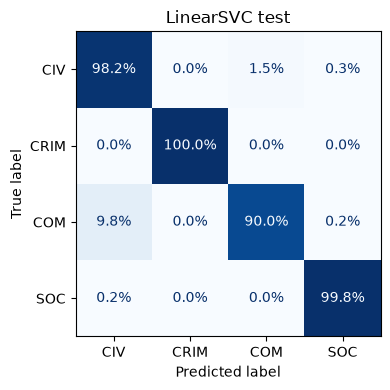

In [24]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, svc_test_predictions, labels=LABELS,
    normalize="true", values_format=".1%", cmap="Blues", colorbar=False, ax=ax,
)
ax.set_title("LinearSVC test")
plt.tight_layout()
plt.show()


<a id="juribert"></a>
## 4. JuriBERT

### 4.1 Model

[JuriBERT-base](https://huggingface.co/dascim/juribert-base) is a French legal language model with a new output layer for four classes. Full fine-tuning used a Colab T4, without LoRA or hyperparameter optimization.

In [14]:
import numpy as np
import torch
from datasets import Dataset
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, f1_score
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

MODEL_ID = "dascim/juribert-base"
MODEL_REVISION = "735b7d1dffc4bd93b78dac1aff6bff448e70c06c"
MAX_LENGTH = 512
NUM_EPOCHS = 5
BERT_DIR = Path("juribert_checkpoints")

label2id = {label: i for i, label in enumerate(LABELS)}
id2label = {i: label for label, i in label2id.items()}

if not (torch.backends.mps.is_available() or torch.cuda.is_available()):
    raise RuntimeError("No MPS or CUDA GPU detected. Check the PyTorch installation before training.")

### 4.2 Prepare text and labels

Long decisions keep the first **255** and last **255 content tokens**, plus two special tokens: **512 tokens in total**. Short decisions stay complete.
Training and prediction use the same rule, which leaves out the middle of long texts.

In [15]:
bert_tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID, revision=MODEL_REVISION, use_fast=True,
)

bert_tokenizer.model_max_length = MAX_LENGTH

In [16]:
CONTENT_TOKENS = MAX_LENGTH - bert_tokenizer.num_special_tokens_to_add(pair=False)
HEAD_TOKENS = CONTENT_TOKENS // 2
TAIL_TOKENS = CONTENT_TOKENS - HEAD_TOKENS


def tokenize_decisions(batch):
    token_sequences = bert_tokenizer(
        batch["text"], add_special_tokens=False, truncation=False,
        return_attention_mask=False, return_token_type_ids=False, verbose=False,
    )["input_ids"]

    input_ids = []
    for tokens in token_sequences:
        if len(tokens) > CONTENT_TOKENS:
            tokens = tokens[:HEAD_TOKENS] + tokens[-TAIL_TOKENS:]
        input_ids.append(bert_tokenizer.build_inputs_with_special_tokens(tokens))

    return {
        "input_ids": input_ids,
        "attention_mask": [[1] * len(tokens) for tokens in input_ids],
    }


bert_dev_tokens = Dataset.from_dict({
    "text": X_dev.tolist(),
    "labels": y_dev.map(label2id).tolist(),
}).map(tokenize_decisions, batched=True, batch_size=64, remove_columns=["text"])

bert_collator = DataCollatorWithPadding(bert_tokenizer, pad_to_multiple_of=8)
print(f"Content tokens: {HEAD_TOKENS} beginning + {TAIL_TOKENS} ending; short decisions stay intact.")
print(f"Training: {len(bert_dev_tokens):,} | Reserved test: {len(X_test):,}")

Content tokens: 255 beginning + 255 ending; short decisions stay intact.
Training: 22,284 | Reserved test: 5,571


### 4.3 Full fine-tuning

All weights are updated with cross-entropy loss and AdamW, using fixed settings:

- Five epochs on all development data.
- Batch size 4, with gradients accumulated over two batches, giving an effective batch size of 8.
- Padding within each batch, with FP16 on the Colab GPU.

Loss is recorded each epoch. The final weights are evaluated once after training.

In [17]:
def load_juribert():
    set_seed(RANDOM_STATE)
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_ID,
        revision=MODEL_REVISION,
        num_labels=len(LABELS),
        label2id=label2id,
        id2label=id2label,
        pad_token_id=bert_tokenizer.pad_token_id,
    )


BERT_TRAINING_PARAMS = {
    "learning_rate": 2e-5,
    "per_device_train_batch_size": 4,
    "per_device_eval_batch_size": 4,
    "gradient_accumulation_steps": 2,
    "weight_decay": 0.01,
    "warmup_ratio": 0.1,
    "optim": "adamw_torch",
    "logging_strategy": "epoch",
    "save_total_limit": 1,
    "dataloader_num_workers": 0,
    "dataloader_pin_memory": False,
    "fp16": torch.cuda.is_available(),
    "seed": RANDOM_STATE,
    "report_to": "none",
}

In [18]:
bert_final_args = TrainingArguments(
    output_dir=str(BERT_DIR),
    num_train_epochs=NUM_EPOCHS,
    eval_strategy="no",
    save_strategy="epoch",
    **BERT_TRAINING_PARAMS,
)
bert_final_trainer = Trainer(
    model=load_juribert(),
    args=bert_final_args,
    train_dataset=bert_dev_tokens,
    processing_class=bert_tokenizer,
    data_collator=bert_collator,
)
_ = bert_final_trainer.train()

Step,Training Loss
2786,0.289500
5572,0.099700
8358,0.064700
11144,0.029200
13930,0.016400


### 4.4 Test evaluation

JuriBERT uses the same test records and metrics as LinearSVC.

In [19]:
bert_test_tokens = Dataset.from_dict({
    "text": X_test.tolist(),
    "labels": y_test.map(label2id).tolist(),
}).map(tokenize_decisions, batched=True, batch_size=64, remove_columns=["text"])

bert_test_output = bert_final_trainer.predict(bert_test_tokens)
bert_test_predictions = np.asarray(LABELS)[bert_test_output.predictions.argmax(axis=-1)]

bert_test_metrics = pd.DataFrame({
    "macro_f1": [f1_score(
        y_test, bert_test_predictions, labels=LABELS, average="macro", zero_division=0,
    )],
    "accuracy": [accuracy_score(y_test, bert_test_predictions)],
}, index=["JuriBERT-base"])
bert_test_report = pd.DataFrame(classification_report(
    y_test, bert_test_predictions, labels=LABELS, output_dict=True, zero_division=0,
)).T.loc[LABELS]
bert_test_report["support"] = bert_test_report["support"].astype(int)

display(bert_test_metrics.round(3))
display(bert_test_report.round(3))

,macro_f1,accuracy
JuriBERT-base,0.958,0.98


,precision,recall,f1-score,support
CIV,0.974,0.987,0.980,2615
CRIM,0.986,0.947,0.966,76
COM,0.915,0.867,0.890,450
SOC,0.997,0.993,0.995,2430


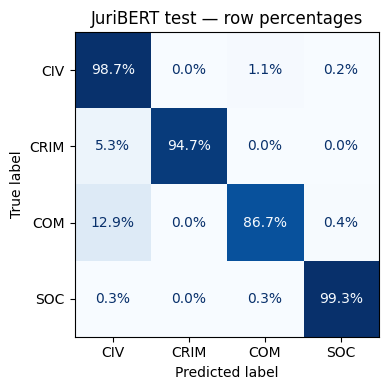

In [20]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, bert_test_predictions, labels=LABELS,
    normalize="true", values_format=".1%", cmap="Blues", colorbar=False, ax=ax,
)
ax.set_title("JuriBERT test")
plt.tight_layout()
plt.show()


<a id="jev"></a>
## 5. Jev: zero-shot classification

### 5.1 Zero-shot classification

Jev 1.14 classifies decisions through TypeSafe's API using category descriptions, without task-specific training or labeled examples.

This section is optional. It requires a TypeSafe API key and model access, and sends each test document to the service. Skip it to run only the local models.

In [1]:
%pip install -q "typesafe-sdk==0.7.5" tqdm

In [2]:
import os
from getpass import getpass
from typesafe_sdk import Choice, TypeSafeAPIError, TypeSafeClient
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, f1_score

JEV_MODEL = "jev-1.14.0"
JEV_EDGE_CHARS = 12_000
jev_api_key = os.environ.get("TYPESAFE_API_KEY") or getpass("TypeSafe API key: ")

jev_label_map = {
    "droit_civil": "CIV",
    "droit_penal": "CRIM",
    "droit_commercial": "COM",
    "droit_social": "SOC",
}

jev_questions = {
    "domain": Choice(
        instructions="Quel est le domaine juridique principal du litige dans cette décision française ?",
        criteria={
            "droit_civil": "Droit civil : famille, personnes, biens, responsabilité et contrats civils, hors droit commercial et social.",
            "droit_penal": "Droit pénal : infractions, poursuites, sanctions et procédure pénale.",
            "droit_commercial": "Droit commercial : sociétés, litiges commerciaux et procédures collectives des entreprises.",
            "droit_social": "Droit social : travail, emploi, relations employeur-salarié et sécurité sociale.",
        },
    ),
}

### 5.2 Classify the test decisions

Each request sends one cleaned decision and fixed category descriptions, excluding the true label and record ID.

The full text is sent first. If it exceeds the context limit, one retry combines the first and last **12,000 characters**.

In [12]:
jev_test_predictions = []
jev_truncated = []

with TypeSafeClient(api_key=jev_api_key, model=JEV_MODEL, timeout=60.0) as client:
    for text in tqdm(X_test, desc="Jev classification"):
        truncated = False
        try:
            response = client.system_one(state=text, questions=jev_questions)
        except TypeSafeAPIError as error:
            if error.status != 400 or "max_tokens_exceeded" not in str(error.body):
                raise
            text = text[:JEV_EDGE_CHARS] + "\n[...]\n" + text[-JEV_EDGE_CHARS:]
            response = client.system_one(state=text, questions=jev_questions)
            truncated = True

        choice = response.choices["domain"].choice
        if choice not in jev_label_map:
            raise ValueError(f"Unexpected Jev category: {choice}")
        jev_test_predictions.append(jev_label_map[choice])
        jev_truncated.append(truncated)

print(f"Classified: {len(jev_test_predictions):,} | Head + tail fallback: {sum(jev_truncated):,}")

Jev classification: 100%|██████████| 5571/5571 [14:59<00:00,  6.19it/s]

Classified: 5,571 | Head + tail fallback: 2


### 5.3 Test evaluation

Jev uses the same test records and metrics as the other models. The classification question stays fixed after evaluation.

In [13]:
assert len(jev_test_predictions) == len(y_test), "Complete classification before evaluation."

jev_test_metrics = pd.DataFrame({
    "macro_f1": [f1_score(
        y_test, jev_test_predictions, labels=LABELS, average="macro", zero_division=0,
    )],
    "accuracy": [accuracy_score(y_test, jev_test_predictions)],
}, index=["Jev (zero-shot)"])
jev_test_report = pd.DataFrame(classification_report(
    y_test, jev_test_predictions, labels=LABELS, output_dict=True, zero_division=0,
)).T.loc[LABELS]
jev_test_report["support"] = jev_test_report["support"].astype(int)

display(jev_test_metrics.round(3))
display(jev_test_report.round(3))

,macro_f1,accuracy
Jev (zero-shot),0.8,0.875


,precision,recall,f1-score,support
CIV,0.966,0.763,0.853,2615
CRIM,0.658,0.987,0.789,76
COM,0.431,0.871,0.576,450
SOC,0.973,0.993,0.983,2430


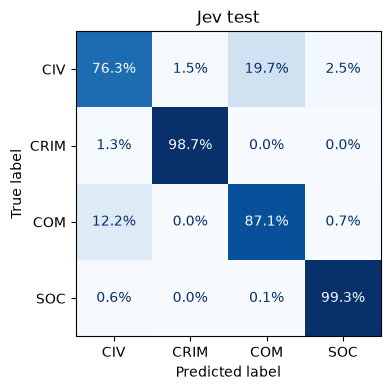

In [14]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, jev_test_predictions, labels=LABELS,
    normalize="true", values_format=".1%", cmap="Blues", colorbar=False, ax=ax,
)
ax.set_title("Jev test")
plt.tight_layout()
plt.show()

<a id="conclusion"></a>
## 6. Conclusion

LinearSVC has the highest test macro-F1 at 0.970, followed by JuriBERT at 0.958 and Jev at 0.800. These results favor the TF-IDF baseline for this dataset under the tested settings. Input lengths and tuning budgets differ between approaches; see the [README](README.md#evaluation-limits) for evaluation limits.